# Lee frame
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/meyer-nils/torch-fem/blob/main/examples/basic/planar/lee_frame.ipynb)
[![Binder](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/meyer-nils/torch-fem/main?labpath=examples/basic/planar/lee_frame.ipynb)

The Lee frame is a classical benchmark for geometrically nonlinear analysis. Two members of length $L=120$ are joined rigidly at a corner and hinged at their far ends, and the horizontal member carries a point load at a fifth of its length from the corner. Past the limit load, the equilibrium path both snaps through, where the load decreases, and snaps back, where the displacement of the load point decreases as well.

Load control fails at the limit point and displacement control of the load point fails at the snap-back. The arc-length method of `solve_arc_length()` treats the load factor $\lambda$ as an unknown and bounds the length $\Delta s$ of each step, $\Delta \mathbf{u} \cdot \Delta \mathbf{u} = \Delta s^2$, so it follows both.

In [1]:
import matplotlib.pyplot as plt
import torch

from torchfem import Planar
from torchfem.elements import linear_to_quadratic
from torchfem.materials import HyperelasticPlaneStrain

torch.set_default_dtype(torch.float64)

## Material

The members are slender, so strains stay small while rotations are large. A Saint Venant-Kirchhoff material with $E=720$ and $\nu=0$ captures this.

In [2]:
def psi(F, params):
    """Saint Venant-Kirchhoff strain energy density for E = 720 and nu = 0."""
    E = 0.5 * (F.transpose(-1, -2) @ F - torch.eye(3))
    return 360.0 * (E * E).sum((-1, -2))


material = HyperelasticPlaneStrain(psi, [])

## Geometry

Both members have a cross-section of depth 2 and width 3, so $EI = 720 \cdot 3 \cdot 2^3 / 12 = 1440$. The L-shape is cut from a grid of quadratic quads, with extra grid lines placing nodes at the hinges and at the load point. The force is a unit load pattern, which the load factor $\lambda$ scales.

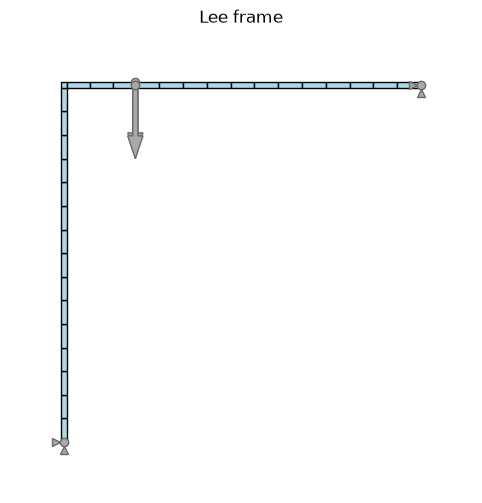

In [3]:
def ticks(a, b):
    """Grid lines from a to b, spaced about 8 apart."""
    return torch.linspace(a, b, max(round((b - a) / 8.0), 1) + 1)


# L-shaped quads cut from a grid, with the hinges and the load on nodes
x = torch.cat([torch.tensor([-1.0]), ticks(1.0, 24.0), ticks(24.0, 120.0)[1:]])
y = torch.cat([ticks(0.0, 119.0), torch.tensor([121.0])])
nodes = torch.cartesian_prod(x, y)
idx = torch.arange(len(nodes)).view(len(x), len(y))
quads = torch.stack([idx[:-1, :-1], idx[1:, :-1], idx[1:, 1:], idx[:-1, 1:]], -1)
center = nodes[quads].mean(-2)
quads = quads[(center[..., 0] < 1.0) | (center[..., 1] > 119.0)]
used, quads = torch.unique(quads, return_inverse=True)
nodes, elements = linear_to_quadratic(nodes[used], quads)

frame = Planar(nodes, elements, material, thickness=3.0)
for hinge in ([0.0, 0.0], [120.0, 120.0]):
    frame.constraints[(nodes == torch.tensor(hinge)).all(1)] = True

# Unit load on top of the beam, a fifth of its length from the corner
load = (nodes[:, 0] == 24.0) & (nodes[:, 1] > 119.0)
frame.forces[load, 1] = -1.0 / int(load.sum())

frame.plot(title="Lee frame")

## Arc-length control

As in Abaqus, the step length $\Delta s$ is set by the load factor increment of the first step, here 0.5. The path ends once a displacement component reaches 100.

In [4]:
u, _, _, _, _, lam = frame.solve_arc_length(
    0.5, 100, max_displacement=100.0, verbose=True
)

# Displacements of the load point and normalized load P L² / EI
v = -u[:, load, 1].mean(dim=1)
h = u[:, load, 0].mean(dim=1)
P = lam * 120.0**2 / 1440.0

────────────────────────────────────────────────────────────────────────────────────────
 model    Planar · 31 elem · 316 dof · float64
 machine  x86_64 · 14 threads · 61 GB RAM
 solver   direct · scipy · cpu
 newton   rtol 1e-08 · atol 1e-06 · <=10 it · finite strain · load increment 0.5
────────────────────────────────────────────────────────────────────────────────────────
       Step  Load factor  Steps  Newton  Krylov  Residual  Wall time


          1       0.4236      1       4       -  1.72e-06     1.40 s


          2       0.7233      1       5       -  6.05e-11     0.29 s


          3       0.9404      1       4       -  9.28e-07     0.30 s
          4        1.106      1       4       -  8.60e-09     0.12 s
          5         1.24      1       4       -  8.20e-11     0.07 s


          6        1.353      1       4       -  6.31e-10     0.06 s
          7        1.451      1       4       -  1.53e-09     0.10 s


          8        1.539      1       4       -  1.04e-09     0.24 s


... (29 outputs left out)

         48      -0.5019      1       4       -  1.36e-10     0.22 s
         49      -0.3963      1       4       -  9.77e-11     0.13 s


         50      -0.2748      1       4       -  9.59e-11     0.27 s
         51        -0.13      1       4       -  1.41e-10     0.17 s


         52      0.05214      1       4       -  5.87e-10     0.31 s
         53       0.2997      1       4       -  8.19e-09     0.20 s


         54       0.6806      1       4       -  5.24e-07     0.17 s
         55        1.415      1       5       -  3.17e-09     0.15 s
────────────────────────────────────────────────────────────────────────────────────────
 converged · 55 steps · 233 Newton iterations · 13.70 s


## Equilibrium path

The load rises to the limit load $PL^2/EI \approx 18.55$ of the beam benchmark, then decreases while the frame snaps through. Further on, the vertical displacement of the load point decreases as well: the frame snaps back. The horizontal displacement keeps growing along the whole path.

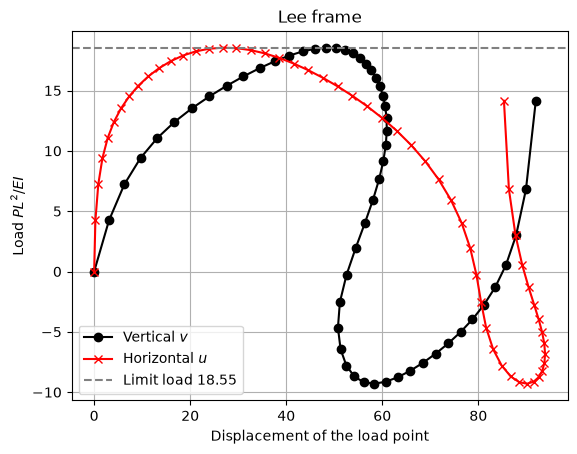

In [5]:
plt.plot(v, P, "o-", color="black", label="Vertical $v$")
plt.plot(h, P, "x-", color="red", label="Horizontal $u$")
plt.axhline(18.55, color="gray", linestyle="--", label="Limit load 18.55")
plt.xlabel("Displacement of the load point")
plt.ylabel("Load $PL^2/EI$")
plt.title("Lee frame")
plt.legend()
plt.grid()

## Deformed shapes

The deformed frame at the limit load, at the snap-back, at the smallest load and at the end of the path.

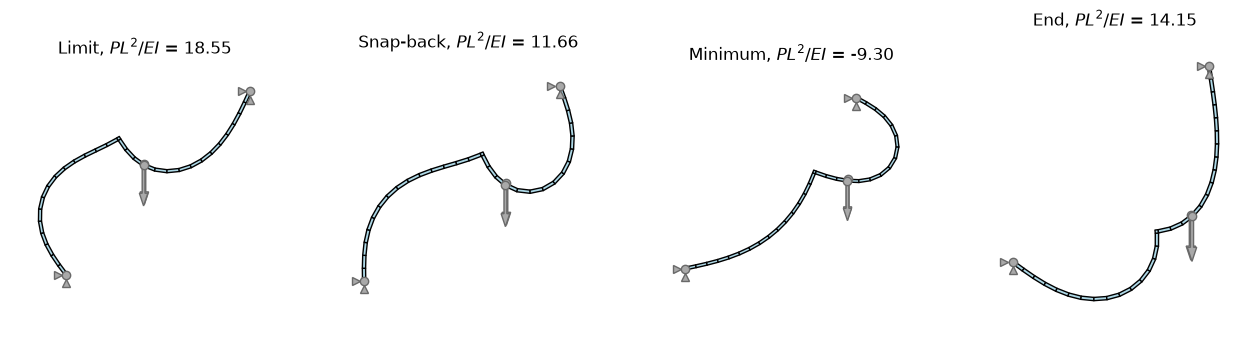

In [6]:
i_limit = int(P.argmax())
i_back = i_limit + int(torch.nonzero(v[i_limit:].diff() < 0.0)[0])
i_min = int(P.argmin())
fig, axs = plt.subplots(1, 4, figsize=(16, 4))
for ax, i, name in zip(
    axs, [i_limit, i_back, i_min, len(P) - 1], ["Limit", "Snap-back", "Minimum", "End"]
):
    frame.plot(u=u[i], ax=ax, title=f"{name}, $PL^2/EI$ = {P[i]:.2f}")